In [3]:
import pandas as pd
import numpy as np

In [4]:
data= {
    "Students":["A","B","C","D","E","F","G","H","I","J"],
    "Marks":[50,55,60,62,65,68,70,72,75,150]
}

In [5]:
df = pd.DataFrame(data)
print(df)

  Students  Marks
0        A     50
1        B     55
2        C     60
3        D     62
4        E     65
5        F     68
6        G     70
7        H     72
8        I     75
9        J    150


In [6]:
Q1= df["Marks"].quantile(0.25)

In [7]:
print(Q1)

60.5


In [8]:
Q3= df["Marks"].quantile(0.75)

In [9]:
print(Q3)

71.5


In [10]:
IQR= Q3-Q1
print(IQR)

11.0


In [11]:
lower_limit = Q1-(1.5*IQR)
upper_limit = Q3+(1.5*IQR)

In [12]:
print(upper_limit)
print(lower_limit)

88.0
44.0


In [13]:
outliers = df[
    (df["Marks"] < lower_limit) |
    (df["Marks"] > upper_limit)
]

In [14]:
print(outliers)

  Students  Marks
9        J    150


In [15]:
df["Marks_Treated"]= np.where(
df["Marks"]> upper_limit,
    upper_limit,
    np.where(
        df["Marks"]< lower_limit,
        lower_limit,
        df["Marks"]
    )
)

In [16]:
df_capped = df.copy()
df_capped["Marks"]= df_capped["Marks"].clip(
lower=lower_limit,
upper=upper_limit
)

In [17]:
print(df_capped)

  Students  Marks  Marks_Treated
0        A     50           50.0
1        B     55           55.0
2        C     60           60.0
3        D     62           62.0
4        E     65           65.0
5        F     68           68.0
6        G     70           70.0
7        H     72           72.0
8        I     75           75.0
9        J     88           88.0


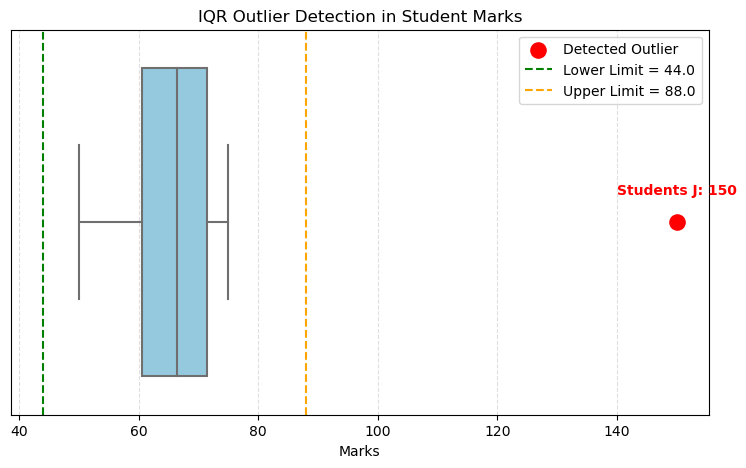

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the box plot
plt.figure(figsize=(9, 5))

sns.boxplot(x=df["Marks"], color="skyblue")

# Highlight the outliers detected by the IQR method
plt.scatter(
    outliers["Marks"],
    [0] * len(outliers),
    color="red",
    s=120,
    label="Detected Outlier",
    zorder=5
)

# Label each detected outlier
for _, row in outliers.iterrows():
    plt.annotate(
        f'Students {row["Students"]}: {row["Marks"]}',
        (row["Marks"], 0),
        xytext=(0, 20),
        textcoords="offset points",
        ha="center",
        color="red",
        fontweight="bold"
    )

# Display IQR limits
plt.axvline(
    lower_limit, color="green", linestyle="--",
    label=f"Lower Limit = {lower_limit}"
)
plt.axvline(
    upper_limit, color="orange", linestyle="--",
    label=f"Upper Limit = {upper_limit}"
)

plt.title("IQR Outlier Detection in Student Marks")
plt.xlabel("Marks")
plt.yticks([])
plt.legend()
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.show()